In [1]:
import re
import json
import glob
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

INPUT = "/kaggle/input/datasets/nocturnalnerd18"
SRC = f"{INPUT}/patch-llava-circuit-signed"
OUT_DIR = "/kaggle/working"
HELD = ["test"]
N_BOOT = 1000
TARGET = 0.8


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


with open(f"{SRC}/circuit_meta.json") as f:
    cm = json.load(f)
STEP_NAMES = cm["step_names"]
POS_STEPS, NEG_STEPS, SIGNED_STEPS = cm["pos_steps"], cm["neg_steps"], cm["signed_steps"]
CORE_COMPS = [tuple(c) for c in cm["core"]]
RANKED_POS = [tuple(c) for c in cm["ranked_pos"]]
RANKED_NEG = [tuple(c) for c in cm["ranked_neg"]]


def comp_name(kind, layer, head, group):
    base = f"L{layer} H{head}" if kind == "head" else f"L{layer} MLP"
    return f"{base} {group}"


PROMOTERS = [c for c in CORE_COMPS if comp_name(*c) in set(cm["promoters"])]
BRAKES = [c for c in CORE_COMPS if comp_name(*c) in set(cm["brakes"])]
assert len(PROMOTERS) + len(BRAKES) == len(CORE_COMPS)


def step_components(name):
    if name == "core":
        return list(CORE_COMPS)
    if name == "promoters":
        return list(PROMOTERS)
    if name == "brakes":
        return list(BRAKES)
    if name.startswith("P+pos"):
        return list(PROMOTERS) + RANKED_POS[:int(name[5:])]
    if name.startswith("B+neg"):
        return list(BRAKES) + RANKED_NEG[:int(name[5:])]
    k = int(name[6:])
    return list(CORE_COMPS) + RANKED_POS[:k] + RANKED_NEG[:k]


def distinct(comps):
    return len({(k, l, h) for k, l, h, g in comps})


entries = []
for path in sorted(glob.glob(f"{SRC}/C_batch_*.pt"), key=batch_number):
    entries.extend(torch.load(path))
good = [e for e in entries if e["ok"] and bool(np.isfinite(e["curve"].numpy()).all())]
print(f"{len(entries)} entries, {len(good)} ok and finite")

CV = np.stack([e["curve"].numpy() for e in good]).astype(np.float64)
dc = np.array([e["delta_clean"] for e in good])
dk = np.array([e["delta_corrupt"] for e in good])
sign = np.array([e["sign"] for e in good])
role = np.array([e["stratum"] for e in good])
split = np.array([e["split"] for e in good])
uid = np.array([e["uid"] for e in good])
fy = np.flatnonzero(role == "false_yes")
ct = np.flatnonzero(role == "true_yes")
S = len(STEP_NAMES)
si = {n: i for i, n in enumerate(STEP_NAMES)}
n_comp = [len(step_components(n)) for n in STEP_NAMES]
n_dist = [distinct(step_components(n)) for n in STEP_NAMES]
held_mask = np.isin(split, HELD)
rng = np.random.default_rng(1)
print("core:", [comp_name(*c) for c in CORE_COMPS])
print("promoters:", [comp_name(*c) for c in PROMOTERS])
print("brakes:", [comp_name(*c) for c in BRAKES])
print(f"core has {len(CORE_COMPS)} listed components and {distinct(CORE_COMPS)} distinct cells; promoters {distinct(PROMOTERS)}; brakes {distinct(BRAKES)}")
print("top positive additions:", [comp_name(*c) for c in RANKED_POS[:8]])
print("top negative additions:", [comp_name(*c) for c in RANKED_NEG[:8]])

240 entries, 240 ok and finite
core: ['L10 MLP visual', 'L11 H26 text', 'L12 H13 text', 'L16 H15 all', 'L16 H0 all', 'L16 MLP all', 'L16 MLP tail', 'L16 H15 tail', 'L17 MLP all', 'L17 MLP tail', 'L28 MLP all', 'L28 MLP tail', 'L31 MLP all', 'L18 MLP tail', 'L18 MLP all']
promoters: ['L11 H26 text', 'L16 MLP all', 'L16 MLP tail', 'L17 MLP all', 'L17 MLP tail', 'L18 MLP tail', 'L18 MLP all']
brakes: ['L10 MLP visual', 'L12 H13 text', 'L16 H15 all', 'L16 H0 all', 'L16 H15 tail', 'L28 MLP all', 'L28 MLP tail', 'L31 MLP all']
core has 15 listed components and 10 distinct cells; promoters 4; brakes 6
top positive additions: ['L15 MLP all', 'L11 H26 all', 'L6 MLP all', 'L30 MLP all', 'L12 H25 all', 'L2 MLP all', 'L11 H17 all', 'L13 MLP all']
top negative additions: ['L14 MLP all', 'L12 H13 all', 'L11 H9 all', 'L7 MLP all', 'L11 H3 all', 'L20 MLP all', 'L29 MLP all', 'L11 MLP all']


In [2]:
def share_sums(ix):
    den = (dk[ix] - dc[ix]).sum()
    knock = (CV[ix, :, 0] - dc[ix, None]).sum(0) / den
    restored = (CV[ix, :, 1] - dk[ix, None]).sum(0) / -den
    return np.stack([knock, restored], 1)


def share_ci(ix, nb=N_BOOT):
    point = share_sums(ix)
    draws = rng.integers(0, len(ix), size=(nb, len(ix)))
    boots = np.stack([share_sums(ix[d]) for d in draws])
    return point, np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)


point, lo, hi = share_ci(fy)
tr = np.flatnonzero((role == "false_yes") & ~held_mask)
te = np.flatnonzero((role == "false_yes") & held_mask)
p_tr, p_te = share_sums(tr), share_sums(te) if len(te) >= 5 else None
table = pd.DataFrame({"listed": n_comp, "distinct": n_dist}, index=STEP_NAMES)
table["knockout"] = [f"{point[i, 0]:+.2f} [{lo[i, 0]:+.2f}, {hi[i, 0]:+.2f}]" for i in range(S)]
table["restored"] = [f"{point[i, 1]:+.2f} [{lo[i, 1]:+.2f}, {hi[i, 1]:+.2f}]" for i in range(S)]
table["ko train+val"] = [f"{p_tr[i, 0]:+.2f}" for i in range(S)]
table["ko held-out"] = [f"{p_te[i, 0]:+.2f}" if p_te is not None else "n/a" for i in range(S)]
table["re train+val"] = [f"{p_tr[i, 1]:+.2f}" for i in range(S)]
table["re held-out"] = [f"{p_te[i, 1]:+.2f}" if p_te is not None else "n/a" for i in range(S)]
print(f"--- driven false_yes shares: all {len(fy)} questions, train+val {len(tr)}, held-out {len(te)}; 95% interval over questions ---")
print(table.to_string())
print("ratio-of-sums shares of the clean to corrupt change; knockout negative means the set is a brake")

print("--- steps with knockout and restored both at least", TARGET, "on all, train+val and held-out ---")
for i in range(S):
    row = [point[i, 0], point[i, 1], p_tr[i, 0], p_tr[i, 1]] + ([p_te[i, 0], p_te[i, 1]] if p_te is not None else [])
    if min(row) >= TARGET:
        print(f"{STEP_NAMES[i]:10s} listed {n_comp[i]:4d} distinct {n_dist[i]:4d}")

--- driven false_yes shares: all 120 questions, train+val 103, held-out 17; 95% interval over questions ---
           listed  distinct              knockout              restored ko train+val ko held-out re train+val re held-out
core           15        10  +0.19 [+0.13, +0.25]  +0.25 [+0.19, +0.30]        +0.17       +0.32        +0.23       +0.32
promoters       7         4  +0.64 [+0.60, +0.66]  +0.54 [+0.50, +0.57]        +0.63       +0.64        +0.53       +0.57
brakes          8         6  -0.77 [-0.89, -0.67]  -0.54 [-0.64, -0.45]        -0.82       -0.52        -0.56       -0.43
P+pos8         15        11  +1.18 [+1.14, +1.22]  +0.95 [+0.92, +0.98]        +1.18       +1.17        +0.95       +0.95
P+pos16        23        19  +1.13 [+1.10, +1.16]  +1.03 [+1.01, +1.06]        +1.13       +1.14        +1.04       +0.99
P+pos32        39        35  +0.97 [+0.95, +0.99]  +1.02 [+1.00, +1.03]        +0.96       +1.00        +1.01       +1.02
P+pos64        71        67  +1.05 [+1

In [3]:
pairs = sorted(set(uid[fy]) & set(uid[ct]))
fy_ix = {u: i for u, i in zip(uid[fy], fy)}
ct_ix = {u: i for u, i in zip(uid[ct], ct)}
a_ix = np.array([fy_ix[u] for u in pairs])
b_ix = np.array([ct_ix[u] for u in pairs])
held_pairs = np.flatnonzero(held_mask[a_ix])
sup_ko = -sign[:, None] * (CV[:, :, 0] - dc[:, None])
sup_re = sign[:, None] * (CV[:, :, 1] - dk[:, None])


def spec(arr, sel, nb=N_BOOT):
    diff = (arr[a_ix] - arr[b_ix])[sel]
    draws = rng.integers(0, len(sel), size=(nb, len(sel)))
    means = diff[draws].mean(1)
    return diff.mean(0), np.percentile(means, 2.5, axis=0), np.percentile(means, 97.5, axis=0)


all_sel = np.arange(len(pairs))
rows = {}
for nm, arr in [("knockout", sup_ko), ("restored", sup_re)]:
    m_all, l_all, u_all = spec(arr, all_sel)
    m_te, l_te, u_te = spec(arr, held_pairs) if len(held_pairs) >= 5 else (None, None, None)
    rows[nm] = (m_all, l_all, u_all, m_te, l_te, u_te)
out = pd.DataFrame({"distinct": n_dist}, index=STEP_NAMES)
for nm in ("knockout", "restored"):
    m_all, l_all, u_all, m_te, l_te, u_te = rows[nm]
    out[f"{nm} all"] = [f"{m_all[i]:+.3f} [{l_all[i]:+.3f}, {u_all[i]:+.3f}]" for i in range(S)]
    out[f"{nm} held-out"] = [f"{m_te[i]:+.3f} [{l_te[i]:+.3f}, {u_te[i]:+.3f}]" if m_te is not None else "n/a" for i in range(S)]
print(f"--- specificity: false_yes minus matched true_yes support for Yes, logits, mean [95% interval]; all {len(pairs)} units, held-out {len(held_pairs)} units ---")
print(out.to_string())

print("--- steps whose interval excludes 0 in both configs on all units ---")
for i in range(S):
    ok_ = all(rows[nm][1][i] > 0 or rows[nm][2][i] < 0 for nm in ("knockout", "restored"))
    same = np.sign(rows["knockout"][0][i]) == np.sign(rows["restored"][0][i])
    if ok_ and same:
        print(f"{STEP_NAMES[i]:10s} knockout {rows['knockout'][0][i]:+.3f} restored {rows['restored'][0][i]:+.3f}")

print("--- additivity: promoters plus brakes against the core, shares ---")
for j, nm in enumerate(["knockout", "restored"]):
    print(f"{nm:9s} promoters {point[si['promoters'], j]:+.2f} + brakes {point[si['brakes'], j]:+.2f} = {point[si['promoters'], j] + point[si['brakes'], j]:+.2f} | core {point[si['core'], j]:+.2f}")

--- specificity: false_yes minus matched true_yes support for Yes, logits, mean [95% interval]; all 120 units, held-out 17 units ---
           distinct             knockout all        knockout held-out             restored all        restored held-out
core             10  -0.015 [-0.155, +0.138]  -0.149 [-0.569, +0.254]  +0.059 [-0.103, +0.230]  -0.214 [-0.591, +0.166]
promoters         4  +0.366 [+0.268, +0.464]  +0.275 [+0.013, +0.503]  +0.266 [+0.161, +0.380]  +0.277 [+0.040, +0.499]
brakes            6  -0.668 [-0.863, -0.477]  -0.637 [-1.303, +0.013]  -0.718 [-0.925, -0.506]  -1.057 [-1.606, -0.512]
P+pos8           11  +0.257 [+0.144, +0.374]  +0.166 [-0.108, +0.442]  +0.362 [+0.217, +0.503]  +0.348 [+0.006, +0.655]
P+pos16          19  +0.113 [+0.004, +0.237]  +0.064 [-0.198, +0.323]  +0.241 [+0.110, +0.378]  +0.082 [-0.211, +0.361]
P+pos32          35  +0.015 [-0.085, +0.111]  -0.108 [-0.381, +0.152]  +0.197 [+0.074, +0.335]  +0.072 [-0.191, +0.327]
P+pos64          67  +0.051

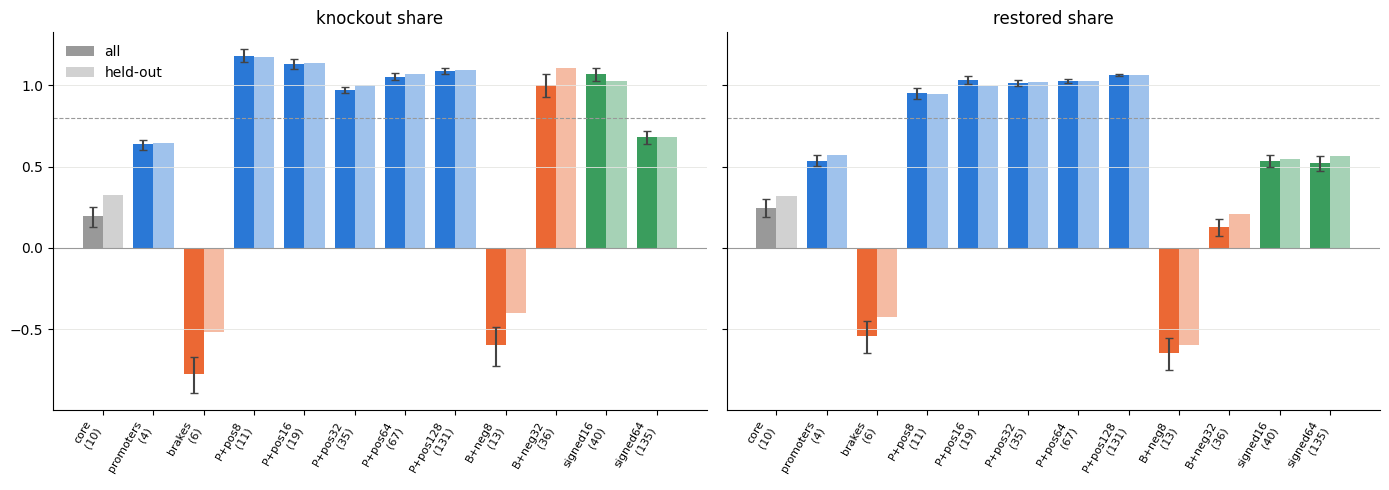

In [4]:
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#999999", "#3a9d5d"
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
xs = np.arange(S)
cols = [ORANGE if n == "brakes" or n.startswith("B+") else BLUE if n == "promoters" or n.startswith("P+") else GREEN if n.startswith("signed") else GREY for n in STEP_NAMES]
for ax, j, title in [(axes[0], 0, "knockout share"), (axes[1], 1, "restored share")]:
    ax.bar(xs - 0.2, point[:, j], width=0.4, color=cols, label="all")
    if p_te is not None:
        ax.bar(xs + 0.2, p_te[:, j], width=0.4, color=cols, alpha=0.45, label="held-out")
    ax.errorbar(xs - 0.2, point[:, j], yerr=[point[:, j] - lo[:, j], hi[:, j] - point[:, j]], fmt="none", ecolor="#444444", capsize=3)
    ax.axhline(TARGET, color=GREY, lw=0.8, ls="--")
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{n}\n({d})" for n, d in zip(STEP_NAMES, n_dist)], rotation=60, ha="right", fontsize=8)
    ax.set_title(title)
    ax.grid(color="#e5e5e2", lw=0.6, axis="y")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/circuit_signed_split.png", dpi=150)
plt.show()

summary = {
    "n_ok": len(good), "n_false_yes": int(len(fy)), "n_held_out_false_yes": int(len(te)), "n_pairs": len(pairs), "n_held_out_pairs": int(len(held_pairs)),
    "step_names": STEP_NAMES, "listed": n_comp, "distinct": n_dist,
    "shares": point.tolist(), "ci_lo": lo.tolist(), "ci_hi": hi.tolist(),
    "shares_train": p_tr.tolist(), "shares_held": p_te.tolist() if p_te is not None else None,
    "spec_knockout": rows["knockout"][0].tolist(), "spec_restored": rows["restored"][0].tolist(),
}
with open(f"{OUT_DIR}/circuit_signed_split.json", "w") as f:
    json.dump(summary, f)